# Classic SVM — Bars and Stripes

Baseline clásico (SVM RBF) sobre el dataset cuántico [Bars and Stripes](https://pennylane.ai/datasets/bars-and-stripes) de PennyLane.

Mismo protocolo que `Classic_SVM_Iris`: split estratificado, `MinMaxScaler` a `[0, π]`, métricas train/test y export JSON.


## Librerias


In [1]:
# 1. Import all libraries
import json
import time
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from pennylane.data import Dataset
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

np.random.seed(123)



## Data

Imágenes oficiales PennyLane (`4×4` → 16 features). Se abre el `.h5` en modo lectura y solo se materializa ese tamaño (evitar `qml.data.load()`, que carga 4/8/16/32 y puede agotar memoria).


In [2]:
DATASET_URL = (
    "https://datasets.cloud.pennylane.ai/datasets/h5/"
    "other/BarsAndStripes/BarsAndStripes_BarsAndStripes.h5"
)
IMAGE_SIZE = "4"  # 4x4 pixels -> 16 features


def resolve_dataset_path() -> Path:
    """Busca el .h5 en caches locales típicos de PennyLane."""
    candidates = [
        Path.cwd() / "datasets" / "other" / "BarsAndStripes" / "BarsAndStripes_BarsAndStripes.h5",
        Path.cwd().resolve().parent / "datasets" / "other" / "BarsAndStripes" / "BarsAndStripes_BarsAndStripes.h5",
    ]
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        candidates.append(
            base / "datasets" / "other" / "BarsAndStripes" / "BarsAndStripes_BarsAndStripes.h5"
        )
    for path in candidates:
        if path.is_file():
            return path
    return candidates[0]


def ensure_bars_and_stripes(path: Path | None = None) -> Path:
    path = resolve_dataset_path() if path is None else Path(path)
    if path.is_file():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading PennyLane bars-and-stripes -> {path} (one-time, ~750MB)")
    urllib.request.urlretrieve(DATASET_URL, path)
    return path


def load_bars_and_stripes(image_size: str = IMAGE_SIZE):
    path = ensure_bars_and_stripes()
    ds = Dataset.open(path, "r")
    try:
        X_train = np.asarray(ds.train[image_size]["inputs"], dtype=float)
        y_train = np.asarray(ds.train[image_size]["labels"], dtype=float)
        X_test = np.asarray(ds.test[image_size]["inputs"], dtype=float)
        y_test = np.asarray(ds.test[image_size]["labels"], dtype=float)
    finally:
        ds.close()
    return X_train, y_train, X_test, y_test


print("Loading PennyLane 'bars-and-stripes' (image_size=4)...")
X_train_official, y_train_official, X_test_official, y_test_official = load_bars_and_stripes(IMAGE_SIZE)

print(
    f"Official splits -> train: {X_train_official.shape}, "
    f"test: {X_test_official.shape}"
)
print("Label values (train):", np.unique(y_train_official, return_counts=True))



Loading PennyLane 'bars-and-stripes' (image_size=4)...
Official splits -> train: (1000, 16), test: (200, 16)
Label values (train): (array([-1.,  1.]), array([514, 486]))


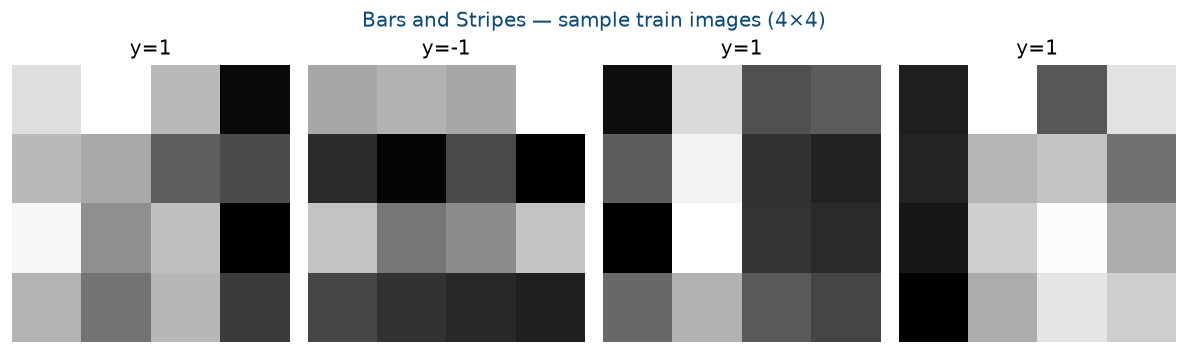

In [3]:
# Preview: first samples as 4x4 images + label
fig, axs = plt.subplots(1, 4, figsize=(10, 3), dpi=120)
for i, ax in enumerate(axs):
    ax.imshow(X_train_official[i].reshape(4, 4), cmap="gray")
    ax.set_title(f"y={int(y_train_official[i])}")
    ax.axis("off")
fig.suptitle("Bars and Stripes — sample train images (4×4)", color="#0E4A75")
plt.tight_layout()
plt.show()



## Data Preparation

Se unen train/test oficiales, se mapean etiquetas `{-1,1}→{0,1}` y se aplica el mismo protocolo Iris: `test_size=0.4`, `random_state=123`, `stratify`, `MinMaxScaler` a `[0, π]`.


In [4]:
# Combine official splits into one pool, then re-split with Iris protocol
X = np.concatenate([X_train_official, X_test_official], axis=0)
y = np.concatenate([y_train_official, y_test_official], axis=0)
y = np.where(y <= 0, 0, 1).astype(int)

n_features = X.shape[1]
print(f"Combined dataset: n={len(X)}, features={n_features}, classes={np.unique(y, return_counts=True)}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=123, stratify=y
)

print(f"Custom Dataset Loaded: Train={len(X_train)}, Test={len(X_test)}")

minmax = MinMaxScaler(feature_range=(0, np.pi))
X_train = minmax.fit_transform(X_train)
X_test = minmax.transform(X_test)
X_test = np.clip(X_test, 0, np.pi)

print(f"Final shapes -> Train: {X_train.shape}, Test: {X_test.shape}")



Combined dataset: n=1200, features=16, classes=(array([0, 1]), array([625, 575]))
Custom Dataset Loaded: Train=720, Test=480
Final shapes -> Train: (720, 16), Test: (480, 16)


## Classic SVM


In [5]:
class ClassicSVM:
    def __init__(self):
        self.model = SVC(kernel="rbf", random_state=42)

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict(self, X):
        return self.model.predict(X)

    def decision_function(self, X):
        return self.model.decision_function(X)



## Entrenamiento Classic SVM
